# Textile Defect Detection — YOLOv8 Training

This notebook trains an initial YOLOv8s object detection model
for textile defect detection using the provided dataset.

### Task 2 Objectives
- Train the initial YOLOv8 model
- Evaluate model performance using mAP metrics
- Generate annotated predictions on the test set
- Export three high-quality inference results
- Save model checkpoints and results to Google Drive

## 1. Connect Google Drive


In [23]:
from google.colab import drive

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Define Dataset and Output Paths


In [24]:
import os

DRIVE_ROOT = "/content/drive/MyDrive/Textile_Defect_Training"

DATASET_ROOT = "/content/textile_dataset/final_dataset"
DATA_YAML = f"{DATASET_ROOT}/data_colab.yaml"

TRAINING_OUTPUT = f"{DRIVE_ROOT}/Training_Results"
INFERENCE_OUTPUT = f"{DRIVE_ROOT}/Test_Inference"

## 3. Verify GPU Environment

YOLOv8 training was performed using the available NVIDIA Tesla T4 GPU.

In [25]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU count:", torch.cuda.device_count())

    total_memory = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f"GPU VRAM: {total_memory:.2f} GB")
else:
    print("❌ GPU NOT AVAILABLE")


PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
GPU count: 1
GPU VRAM: 14.56 GB


## 4. Extract Dataset

In [26]:
import zipfile
import os
import time

zip_path = "/content/drive/MyDrive/Hangzhou_Textile_POC/textile_defect_yolov8_final.zip"
extract_path = "/content/textile_dataset"

print("ZIP exists:", os.path.exists(zip_path))

if not os.path.exists(extract_path):
    print("Extracting dataset...")
    start_time = time.time()

    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

    elapsed = time.time() - start_time
    print(f"Extraction completed in {elapsed/60:.2f} minutes.")
else:
    print("Dataset already extracted. Skipping extraction.")

ZIP exists: True
Extracting dataset...
Extraction completed in 0.98 minutes.


## 5. Verify Dataset Structure

Before training, the train, validation, and test splits are checked to ensure
that images and corresponding YOLO annotation files are present.

In [27]:
import os

dataset_root = "/content/textile_dataset/final_dataset"

splits = ["train", "val", "test"]

print("DATASET ROOT:")
print(dataset_root)
print("\n" + "=" * 60)

for split in splits:
    image_dir = os.path.join(dataset_root, "images", split)
    label_dir = os.path.join(dataset_root, "labels", split)

    images = [
        f for f in os.listdir(image_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
    ]

    labels = [
        f for f in os.listdir(label_dir)
        if f.lower().endswith(".txt")
    ]

    image_bases = {os.path.splitext(f)[0] for f in images}
    label_bases = {os.path.splitext(f)[0] for f in labels}

    missing_labels = image_bases - label_bases
    missing_images = label_bases - image_bases

    print(f"\n{split.upper()}")
    print("-" * 30)
    print(f"Images: {len(images)}")
    print(f"Labels: {len(labels)}")
    print(f"Images without labels: {len(missing_labels)}")
    print(f"Labels without images: {len(missing_images)}")

print("\n" + "=" * 60)
print("Dataset structure verified.")

DATASET ROOT:
/content/textile_dataset/final_dataset


TRAIN
------------------------------
Images: 3900
Labels: 3900
Images without labels: 0
Labels without images: 0

VAL
------------------------------
Images: 562
Labels: 562
Images without labels: 0
Labels without images: 0

TEST
------------------------------
Images: 280
Labels: 280
Images without labels: 0
Labels without images: 0

Dataset structure verified.


## 6. Install and Import Ultralytics

Ultralytics is installed to provide the YOLOv8 object detection framework.

In [28]:
!pip install -q -U ultralytics


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.6/45.6 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 65.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.9/63.9 kB 6.5 MB/s eta 0:00:00


In [29]:
from ultralytics import YOLO
import ultralytics

print("Ultralytics version:", ultralytics.__version__)
print("YOLO imported successfully!")

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics version: 8.4.121
YOLO imported successfully!


## 7. Configure Dataset

A YOLO-compatible dataset configuration is created for the seven textile
defect classes used in the detection task.

In [30]:
import yaml
import os

dataset_root = "/content/textile_dataset/final_dataset"

data_config = {
    "path": dataset_root,
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": 7,
    "names": [
        "baekra",
        "color issues",
        "contamination",
        "cut",
        "gray stitch",
        "selvet",
        "stain"
    ]
}

colab_yaml = "/content/textile_dataset/final_dataset/data_colab.yaml"

with open(colab_yaml, "w") as f:
    yaml.dump(data_config, f, sort_keys=False)

print("Created:", colab_yaml)

with open(colab_yaml, "r") as f:
    print("\n--- data_colab.yaml ---")
    print(f.read())

Created: /content/textile_dataset/final_dataset/data_colab.yaml

--- data_colab.yaml ---
path: /content/textile_dataset/final_dataset
train: images/train
val: images/val
test: images/test
nc: 7
names:
- baekra
- color issues
- contamination
- cut
- gray stitch
- selvet
- stain



In [31]:
from ultralytics import YOLO

model = YOLO("yolov8s.pt")

print("YOLOv8s model loaded successfully.")

YOLOv8s model loaded successfully.


In [32]:
from pathlib import Path

data_yaml = "/content/textile_dataset/final_dataset/data_colab.yaml"

print("Dataset YAML exists:", Path(data_yaml).exists())

print("\nDataset YAML:")
with open(data_yaml, "r") as f:
    print(f.read())

Dataset YAML exists: True

Dataset YAML:
path: /content/textile_dataset/final_dataset
train: images/train
val: images/val
test: images/test
nc: 7
names:
- baekra
- color issues
- contamination
- cut
- gray stitch
- selvet
- stain



## 8. Prepare Training Output Directory

Training logs, evaluation metrics, plots, and model checkpoints are saved to
Google Drive.

In [33]:
import os

os.makedirs(TRAINING_OUTPUT, exist_ok=True)

print(f"Training output directory: {TRAINING_OUTPUT}")

Training output directory: /content/drive/MyDrive/Textile_Defect_Training/Training_Results


## 9. Train YOLOv8s Model

A pretrained YOLOv8s model is fine-tuned for textile defect detection using
the prepared seven-class dataset.

Training is performed for 20 epochs at an image size of 640 × 640. The
resulting model checkpoints and training metrics are saved to Google Drive.

In [34]:
from ultralytics import YOLO

# Dataset configuration
data_yaml = "/content/textile_dataset/final_dataset/data_colab.yaml"

# Google Drive output folder
output_dir = "/content/drive/MyDrive/Textile_Defect_Training/Training_Results"

# Load pretrained YOLOv8s
model = YOLO("yolov8s.pt")

# Train
results = model.train(
    data=data_yaml,
    epochs=20,
    imgsz=640,
    batch=0.70,
    device=0,
    amp=True,
    workers=4,
    project=output_dir,
    name="yolov8s_textile_initial",
    exist_ok=True,
    pretrained=True,
    plots=True
)

Ultralytics 8.4.121 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=0.7, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/textile_dataset/final_dataset/data_colab.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8

KeyboardInterrupt: 

# Post-Training Verification

After completing YOLOv8 training, the trained model and generated training outputs are verified to ensure that the required checkpoints and evaluation files have been successfully saved to Google Drive.

In [35]:
import os

results_dir = "/content/drive/MyDrive/Textile_Defect_Training/Training_Results/yolov8s_textile_initial"

print("Training results folder exists:", os.path.exists(results_dir))

print("\nFiles saved:")
for item in sorted(os.listdir(results_dir)):
    print(" -", item)

weights_dir = os.path.join(results_dir, "weights")

print("\nWeights folder exists:", os.path.exists(weights_dir))

if os.path.exists(weights_dir):
    print("\nCheckpoint files:")
    for item in sorted(os.listdir(weights_dir)):
        print(" -", item)

Training results folder exists: True

Files saved:
 - BoxF1_curve.png
 - BoxPR_curve.png
 - BoxP_curve.png
 - BoxR_curve.png
 - args.yaml
 - confusion_matrix.png
 - confusion_matrix_normalized.png
 - labels.jpg
 - results.csv
 - results.png
 - train_batch0.jpg
 - train_batch1.jpg
 - train_batch2.jpg
 - train_batch2170.jpg
 - train_batch2171.jpg
 - train_batch2172.jpg
 - val_batch0_labels.jpg
 - val_batch0_pred.jpg
 - val_batch1_labels.jpg
 - val_batch1_pred.jpg
 - val_batch2_labels.jpg
 - val_batch2_pred.jpg
 - weights

Weights folder exists: True

Checkpoint files:
 - best.pt
 - last.pt


## TRAINING VERIFICATION


In [36]:
import os

# ============================================================
# GOOGLE DRIVE TRAINING RESULTS
# ============================================================

drive_training_dir = (
    "/content/drive/MyDrive/"
    "Textile_Defect_Training/Training_Results/"
    "yolov8s_textile_initial"
)

weights_dir = os.path.join(drive_training_dir, "weights")

print("=" * 70)
print("GOOGLE DRIVE TRAINING OUTPUT VERIFICATION")
print("=" * 70)

# 1. Check main folder
print("\n1. Training folder:")
print(drive_training_dir)
print("Exists:", os.path.isdir(drive_training_dir))

# 2. Check weights folder
print("\n2. Weights folder:")
print(weights_dir)
print("Exists:", os.path.isdir(weights_dir))

# 3. Check checkpoints
print("\n3. Checkpoints:")

for filename in ["best.pt", "last.pt"]:
    filepath = os.path.join(weights_dir, filename)

    if os.path.isfile(filepath):
        size_mb = os.path.getsize(filepath) / (1024 ** 2)

        print(f"  ✅ {filename}")
        print(f"     Size: {size_mb:.2f} MB")
        print(f"     Path: {filepath}")
    else:
        print(f"  ❌ {filename} NOT FOUND")

# 4. Check important result files
important_files = [
    "results.csv",
    "results.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
    "BoxF1_curve.png",
    "BoxPR_curve.png",
    "labels.jpg",
    "args.yaml"
]

print("\n4. Important training files:")

for filename in important_files:
    filepath = os.path.join(drive_training_dir, filename)

    if os.path.isfile(filepath):
        size_kb = os.path.getsize(filepath) / 1024
        print(f"  ✅ {filename} ({size_kb:.1f} KB)")
    else:
        print(f"  ❌ {filename} NOT FOUND")

# 5. Show everything in the training directory
print("\n5. Complete Google Drive training folder contents:")

for root, dirs, files in os.walk(drive_training_dir):
    relative = os.path.relpath(root, drive_training_dir)

    if relative == ".":
        print("\n[ROOT]")
    else:
        print(f"\n[{relative}]")

    for file in sorted(files):
        filepath = os.path.join(root, file)
        size_mb = os.path.getsize(filepath) / (1024 ** 2)
        print(f"  - {file} ({size_mb:.2f} MB)")

print("\n" + "=" * 70)
print("VERIFICATION COMPLETE")
print("=" * 70)

GOOGLE DRIVE TRAINING OUTPUT VERIFICATION

1. Training folder:
/content/drive/MyDrive/Textile_Defect_Training/Training_Results/yolov8s_textile_initial
Exists: True

2. Weights folder:
/content/drive/MyDrive/Textile_Defect_Training/Training_Results/yolov8s_textile_initial/weights
Exists: True

3. Checkpoints:
  ✅ best.pt
     Size: 21.45 MB
     Path: /content/drive/MyDrive/Textile_Defect_Training/Training_Results/yolov8s_textile_initial/weights/best.pt
  ✅ last.pt
     Size: 21.45 MB
     Path: /content/drive/MyDrive/Textile_Defect_Training/Training_Results/yolov8s_textile_initial/weights/last.pt

4. Important training files:
  ✅ results.csv (2.6 KB)
  ✅ results.png (263.3 KB)
  ✅ confusion_matrix.png (179.5 KB)
  ✅ confusion_matrix_normalized.png (199.1 KB)
  ✅ BoxP_curve.png (266.1 KB)
  ✅ BoxR_curve.png (269.8 KB)
  ✅ BoxF1_curve.png (322.0 KB)
  ✅ BoxPR_curve.png (197.2 KB)
  ✅ labels.jpg (224.3 KB)
  ✅ args.yaml (1.8 KB)

5. Complete Google Drive training folder contents:

[ROOT]


## VERIFY CLASSES

In [37]:
from ultralytics import YOLO

best_model_path = (
    "/content/drive/MyDrive/"
    "Textile_Defect_Training/Training_Results/"
    "yolov8s_textile_initial/weights/best.pt"
)

model = YOLO(best_model_path)

print("✅ best.pt loaded successfully from Google Drive")
print("Model path:", best_model_path)
print("Number of classes:", len(model.names))
print("Class names:", model.names)

✅ best.pt loaded successfully from Google Drive
Model path: /content/drive/MyDrive/Textile_Defect_Training/Training_Results/yolov8s_textile_initial/weights/best.pt
Number of classes: 7
Class names: {0: 'baekra', 1: 'color issues', 2: 'contamination', 3: 'cut', 4: 'gray stitch', 5: 'selvet', 6: 'stain'}


## RESULTS VALIDATION


In [38]:
# Validate the saved best.pt directly from Google Drive

validation_results = model.val(
    data="/content/textile_dataset/final_dataset/data_colab.yaml",
    split="val",
    imgsz=640,
    batch=18,
    device=0,
    plots=False,
    verbose=True
)

print("\n" + "=" * 60)
print("VALIDATION OF SAVED best.pt")
print("=" * 60)

print(f"mAP50:     {validation_results.box.map50:.4f}")
print(f"mAP50-95:  {validation_results.box.map:.4f}")
print(f"Precision: {validation_results.box.mp:.4f}")
print(f"Recall:    {validation_results.box.mr:.4f}")

Ultralytics 8.4.121 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 11,128,293 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1695.5±631.1 MB/s, size: 171.2 KB)
val: Scanning /content/textile_dataset/final_dataset/labels/val... 562 images, 38 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 562/562 1.2Kit/s 0.5s
val: New cache created: /content/textile_dataset/final_dataset/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 3.4it/s 9.3s
                   all        562        786       0.77      0.748      0.788      0.471
                baekra         48         79      0.778      0.823      0.839      0.572
          color issues         15         30      0.675      0.416      0.512      0.245
         contamination         53         55      0.965          1       0.99      0.537
                   cut         75       

## TEST DATASET FOR INFERENCE


In [39]:
import os

# Test dataset paths
test_images_dir = "/content/textile_dataset/final_dataset/images/test"
test_labels_dir = "/content/textile_dataset/final_dataset/labels/test"

# Get image and label files
image_files = sorted([
    f for f in os.listdir(test_images_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
])

label_files = sorted([
    f for f in os.listdir(test_labels_dir)
    if f.lower().endswith(".txt")
])

# Match filenames without extensions
image_bases = {
    os.path.splitext(f)[0]
    for f in image_files
}

label_bases = {
    os.path.splitext(f)[0]
    for f in label_files
}

missing_labels = image_bases - label_bases
missing_images = label_bases - image_bases

print("=" * 60)
print("TEST DATASET VERIFICATION")
print("=" * 60)

print(f"Test images: {len(image_files)}")
print(f"Test labels: {len(label_files)}")
print(f"Images without labels: {len(missing_labels)}")
print(f"Labels without images: {len(missing_images)}")

print("\nTest image directory:")
print(test_images_dir)

print("\nTest label directory:")
print(test_labels_dir)

print("\nStatus:")

if (
    len(image_files) == 280
    and len(label_files) == 280
    and len(missing_labels) == 0
    and len(missing_images) == 0
):
    print("✅ TEST DATASET IS READY FOR INFERENCE")
else:
    print("⚠️ TEST DATASET NEEDS INVESTIGATION")

TEST DATASET VERIFICATION
Test images: 280
Test labels: 280
Images without labels: 0
Labels without images: 0

Test image directory:
/content/textile_dataset/final_dataset/images/test

Test label directory:
/content/textile_dataset/final_dataset/labels/test

Status:
✅ TEST DATASET IS READY FOR INFERENCE


## INFERENCE


In [40]:
from ultralytics import YOLO
import os

# ============================================================
# VERIFIED BEST MODEL FROM GOOGLE DRIVE
# ============================================================

best_model_path = (
    "/content/drive/MyDrive/"
    "Textile_Defect_Training/Training_Results/"
    "yolov8s_textile_initial/weights/best.pt"
)

# ============================================================
# TEST IMAGES
# ============================================================

test_images_dir = (
    "/content/textile_dataset/final_dataset/images/test"
)

# ============================================================
# GOOGLE DRIVE OUTPUT LOCATION
# ============================================================

inference_dir = (
    "/content/drive/MyDrive/"
    "Textile_Defect_Training/Test_Inference"
)

os.makedirs(inference_dir, exist_ok=True)

# ============================================================
# LOAD VERIFIED MODEL
# ============================================================

model = YOLO(best_model_path)

print("Model loaded successfully from Google Drive:")
print(best_model_path)

print("\nRunning inference on:")
print(test_images_dir)

print("\nSaving predictions to:")
print(inference_dir)

# ============================================================
# RUN INFERENCE
# ============================================================

results = model.predict(
    source=test_images_dir,
    imgsz=640,
    device=0,
    conf=0.25,
    save=True,
    project=inference_dir,
    name="test_predictions",
    exist_ok=True,
    verbose=True
)

print("\n" + "=" * 60)
print("INFERENCE COMPLETED")
print("=" * 60)

Model loaded successfully from Google Drive:
/content/drive/MyDrive/Textile_Defect_Training/Training_Results/yolov8s_textile_initial/weights/best.pt

Running inference on:
/content/textile_dataset/final_dataset/images/test

Saving predictions to:
/content/drive/MyDrive/Textile_Defect_Training/Test_Inference

image 1/280 /content/textile_dataset/final_dataset/images/test/00003932_jpg.rf.cabbaf58e5c34db2ffe2df66ad965f44.jpg: 640x640 1 gray stitch, 16.1ms
image 2/280 /content/textile_dataset/final_dataset/images/test/00004155_jpg.rf.fda6849061cd87c8b3f2085d28e0fe4c.jpg: 640x640 1 gray stitch, 17.0ms
image 3/280 /content/textile_dataset/final_dataset/images/test/00004488_jpg.rf.207e06d40a9bf92c322c7e68109ce3b3.jpg: 640x640 1 gray stitch, 16.2ms
image 4/280 /content/textile_dataset/final_dataset/images/test/00065510_jpg.rf.54b199584b4e152c12acf35aa58d8613.jpg: 640x640 1 gray stitch, 16.2ms
image 5/280 /content/textile_dataset/final_dataset/images/test/006843_jpg.rf.7d6b35a29774a248e7848185c

## INFERENCE VERIFICATION

In [41]:
import os

inference_dir = (
    "/content/drive/MyDrive/"
    "Textile_Defect_Training/Test_Inference/"
    "test_predictions"
)

image_files = sorted([
    f for f in os.listdir(inference_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
])

print("=" * 60)
print("INFERENCE OUTPUT VERIFICATION")
print("=" * 60)

print("Inference folder:")
print(inference_dir)

print(f"\nAnnotated images found: {len(image_files)}")

print("\nFirst 10 files:")
for f in image_files[:10]:
    print(" -", f)

print("\nLast 10 files:")
for f in image_files[-10:]:
    print(" -", f)

print("\n" + "=" * 60)

if len(image_files) == 280:
    print("✅ ALL 280 ANNOTATED INFERENCE IMAGES ARE SAVED")
else:
    print(f"⚠️ Expected 280 images, found {len(image_files)}")

INFERENCE OUTPUT VERIFICATION
Inference folder:
/content/drive/MyDrive/Textile_Defect_Training/Test_Inference/test_predictions

Annotated images found: 280

First 10 files:
 - 00003932_jpg.rf.cabbaf58e5c34db2ffe2df66ad965f44.jpg
 - 00004155_jpg.rf.fda6849061cd87c8b3f2085d28e0fe4c.jpg
 - 00004488_jpg.rf.207e06d40a9bf92c322c7e68109ce3b3.jpg
 - 00065510_jpg.rf.54b199584b4e152c12acf35aa58d8613.jpg
 - 006843_jpg.rf.7d6b35a29774a248e7848185c8764286.jpg
 - 006862_jpg.rf.f9a561d26a9cb18b7b7cc7752b8d6e95.jpg
 - 006863_jpg.rf.da6ca04263898d97eebdabfe350d41f7.jpg
 - 006875_jpg.rf.dfbb3fd8d87667e13647987873fbebfb.jpg
 - 20230712_141336_jpeg_jpg.rf.67998702da1d47f1147519b8bbb419a4.jpg
 - 20230712_141549_jpeg_jpg.rf.b9bf33d920c5f526c393ddb63313b979.jpg

Last 10 files:
 - istockphoto-1148927528-612x612_jpg.rf.b42bfc0a0252ca5358550f56dd0e94e1.jpg
 - photo_2023-11-19_18-10-11_jpg.rf.95bde8d091241308205c3be5e9a9ff10.jpg
 - stock-photo-woman-showing-hole-in-the-clothes-close-up-1788170570-transformed_jpe

## CONTACT SHEET CREATION

created to look for the best class

In [42]:
from PIL import Image, ImageDraw
import os
import math

inference_dir = (
    "/content/drive/MyDrive/"
    "Textile_Defect_Training/Test_Inference/"
    "test_predictions"
)

# Get all inference images
image_files = sorted([
    f for f in os.listdir(inference_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

# Create contact sheets in batches of 50
contact_dir = (
    "/content/drive/MyDrive/"
    "Textile_Defect_Training/Test_Inference/Contact_Sheets"
)

os.makedirs(contact_dir, exist_ok=True)

thumb_w = 240
thumb_h = 200
cols = 5
rows = 10

for batch_start in range(0, len(image_files), 50):

    batch = image_files[batch_start:batch_start + 50]

    sheet = Image.new(
        "RGB",
        (cols * thumb_w, rows * thumb_h),
        "white"
    )

    draw = ImageDraw.Draw(sheet)

    for i, filename in enumerate(batch):

        img_path = os.path.join(inference_dir, filename)

        try:
            img = Image.open(img_path).convert("RGB")
            img.thumbnail((thumb_w - 10, thumb_h - 30))

            x = (i % cols) * thumb_w
            y = (i // cols) * thumb_h

            sheet.paste(
                img,
                (
                    x + (thumb_w - img.width) // 2,
                    y + 5
                )
            )

            draw.text(
                (x + 5, y + thumb_h - 22),
                f"{batch_start + i + 1}: {filename[:25]}",
                fill="black"
            )

        except Exception as e:
            print(f"Could not process {filename}: {e}")

    sheet_path = os.path.join(
        contact_dir,
        f"contact_sheet_{batch_start//50 + 1}.jpg"
    )

    sheet.save(sheet_path, quality=95)

print("=" * 60)
print("CONTACT SHEETS CREATED")
print("=" * 60)

for f in sorted(os.listdir(contact_dir)):
    print("-", f)

print("\nSaved to Google Drive:")
print(contact_dir)

CONTACT SHEETS CREATED
- contact_sheet_1.jpg
- contact_sheet_2.jpg
- contact_sheet_3.jpg
- contact_sheet_4.jpg
- contact_sheet_5.jpg
- contact_sheet_6.jpg

Saved to Google Drive:
/content/drive/MyDrive/Textile_Defect_Training/Test_Inference/Contact_Sheets


## finding strongest class

In [44]:
from ultralytics import YOLO
import os
from collections import defaultdict

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

best_model_path = (
    "/content/drive/MyDrive/"
    "Textile_Defect_Training/Training_Results/"
    "yolov8s_textile_initial/weights/best.pt"
)

test_dir = "/content/textile_dataset/final_dataset/images/test"

# ------------------------------------------------------------
# Load model
# ------------------------------------------------------------

model = YOLO(best_model_path)

# ------------------------------------------------------------
# Get test images
# ------------------------------------------------------------

image_files = sorted([
    f for f in os.listdir(test_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
])

# ------------------------------------------------------------
# Collect strongest predictions by class
# ------------------------------------------------------------

best_by_class = defaultdict(list)

for index, filename in enumerate(image_files, 1):

    image_path = os.path.join(test_dir, filename)

    result = model.predict(
        source=image_path,
        imgsz=640,
        device=0,
        conf=0.25,
        verbose=False
    )[0]

    for box in result.boxes:

        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        class_name = model.names[class_id]

        best_by_class[class_name].append({
            "filename": filename,
            "confidence": confidence,
            "resolution": result.orig_shape,
            "index": index
        })

# ------------------------------------------------------------
# Print top predictions for every class
# ------------------------------------------------------------

print("=" * 80)
print("STRONGEST TEST-SET PREDICTIONS BY DEFECT CLASS")
print("=" * 80)

for class_name in model.names.values():

    predictions = sorted(
        best_by_class[class_name],
        key=lambda x: x["confidence"],
        reverse=True
    )

    print(f"\n{'-' * 80}")
    print(f"CLASS: {class_name}")
    print(f"{'-' * 80}")

    for prediction in predictions[:5]:

        print(
            f"#{prediction['index']:03d} | "
            f"confidence={prediction['confidence']:.3f} | "
            f"resolution={prediction['resolution']} | "
            f"{prediction['filename']}"
        )

print("\n" + "=" * 80)
print("SEARCH COMPLETE")
print("=" * 80)

STRONGEST TEST-SET PREDICTIONS BY DEFECT CLASS

--------------------------------------------------------------------------------
CLASS: baekra
--------------------------------------------------------------------------------
#035 | confidence=0.950 | resolution=(1140, 2026) | 20230719_100220_jpeg_jpg.rf.22f3ea5032d65b69184216c3b5e74976.jpg
#078 | confidence=0.885 | resolution=(1152, 716) | IMG-20230817-WA0060_jpg.rf.b39081cd04cc1a6bf465fb89a5254b2a.jpg
#237 | confidence=0.871 | resolution=(1120, 678) | Snapchat-713102257_jpg.rf.c3aa04d6c8d239658f2a03cc51500a80.jpg
#230 | confidence=0.870 | resolution=(1030, 642) | Snapchat-1693966967_jpg.rf.0b0edca8f482e06caf352b2017199d0e.jpg
#210 | confidence=0.866 | resolution=(1898, 1424) | IMG_20230823_111346_jpg.rf.ae3211631df171193712a20daad3e18c.jpg

--------------------------------------------------------------------------------
CLASS: color issues
--------------------------------------------------------------------------------
#062 | confidenc

## SEARCHING FOR BEST 3 IMAGES

PROPOSED FINAL 3 PITCH IMAGES

#035 - baekra
Filename: 20230719_100220_jpeg_jpg.rf.22f3ea5032d65b69184216c3b5e74976.jpg
Exists: True
Original resolution: (1140, 2026)
Predictions: 1
Box 1: baekra | confidence = 0.950


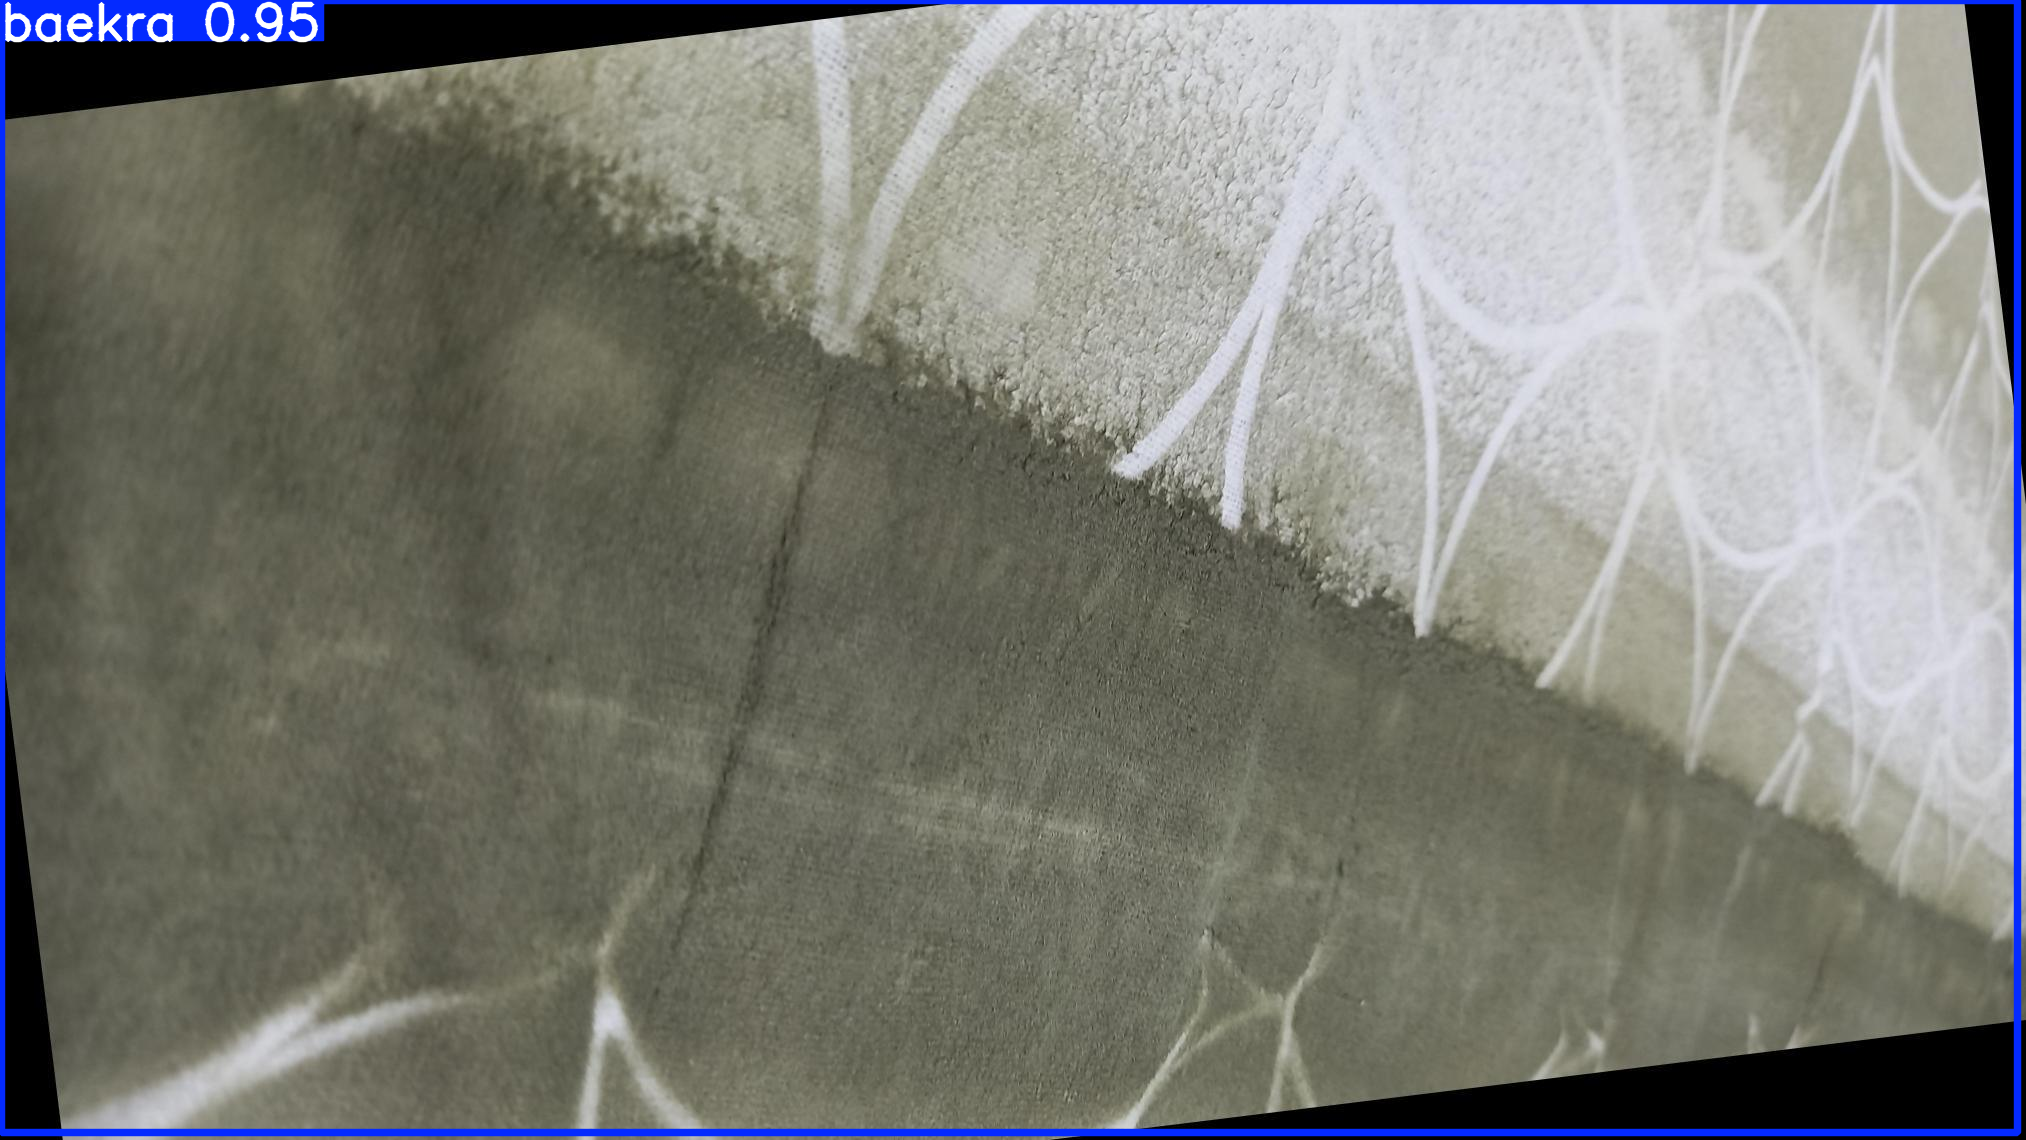


#062 - color issues
Filename: IMG-20230803-WA0065_jpg.rf.63c1771f3fb896daec292733037bf4f0.jpg
Exists: True
Original resolution: (748, 996)
Predictions: 2
Box 1: color issues | confidence = 0.949
Box 2: color issues | confidence = 0.923


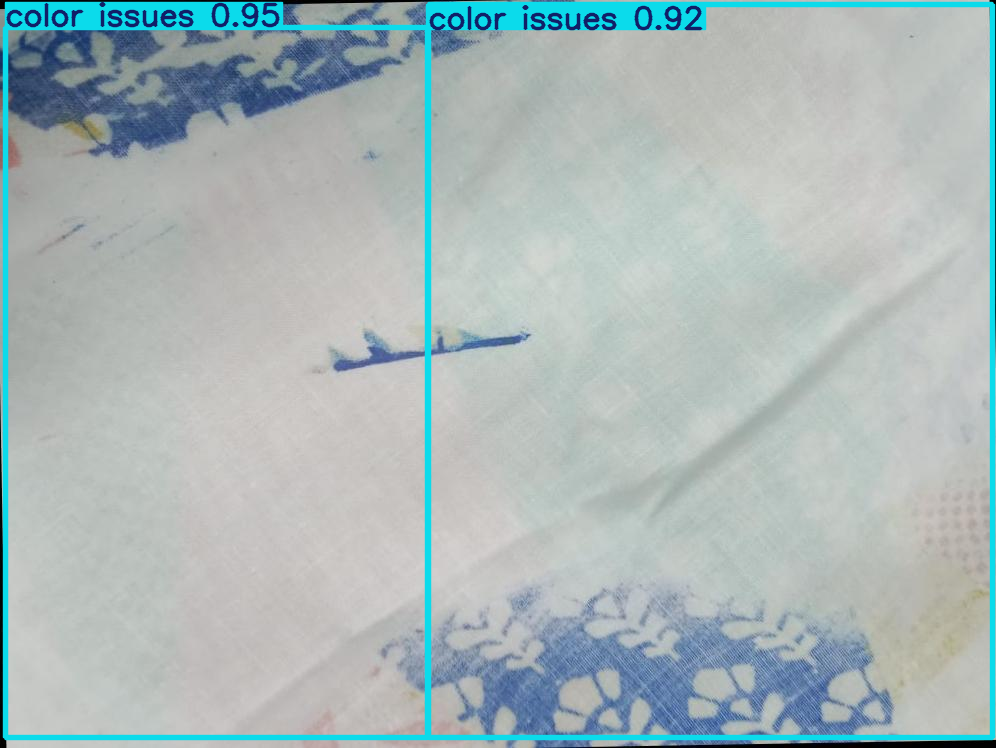


#095 - cut
Filename: IMG-20230818-WA0073_jpg.rf.a8101503d0872dd85ce57b06dc758de6.jpg
Exists: True
Original resolution: (1226, 690)
Predictions: 1
Box 1: cut | confidence = 0.921


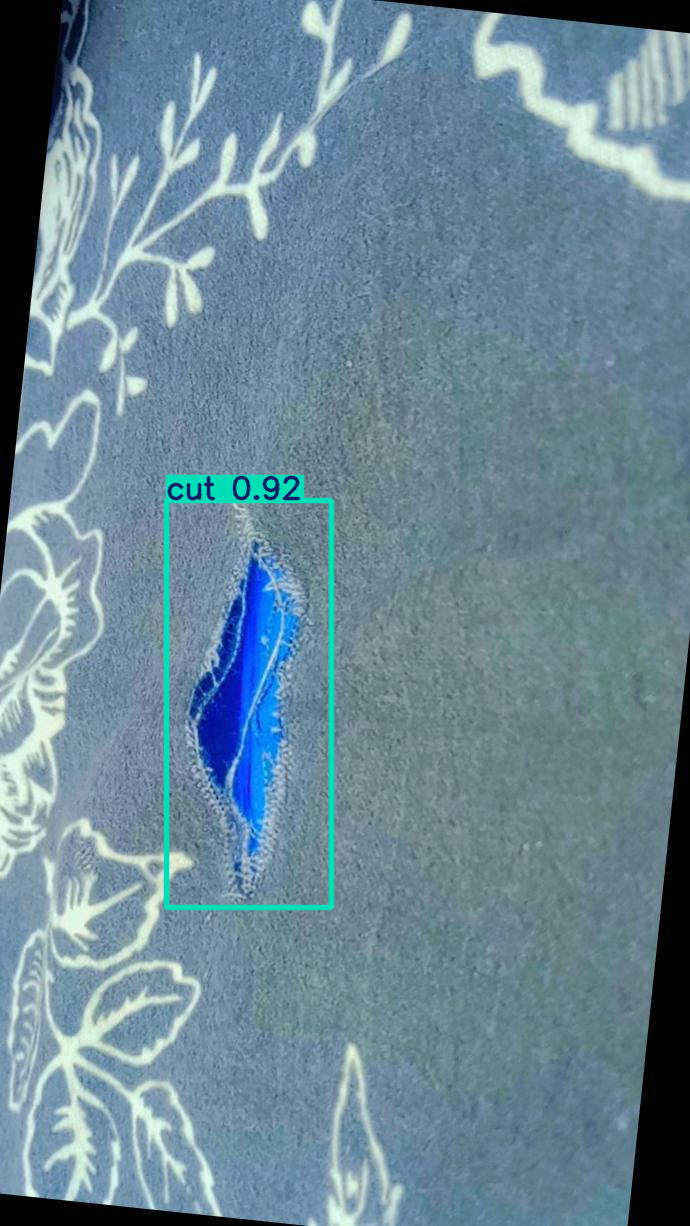


VISUAL INSPECTION COMPLETE


In [45]:
from ultralytics import YOLO
from IPython.display import display
from PIL import Image
import os

# ============================================================
# VERIFIED MODEL
# ============================================================

best_model_path = (
    "/content/drive/MyDrive/"
    "Textile_Defect_Training/Training_Results/"
    "yolov8s_textile_initial/weights/best.pt"
)

test_dir = "/content/textile_dataset/final_dataset/images/test"

# ============================================================
# PROPOSED FINAL 3
# ============================================================

candidates = {
    "#035 - baekra":
        "20230719_100220_jpeg_jpg.rf.22f3ea5032d65b69184216c3b5e74976.jpg",

    "#062 - color issues":
        "IMG-20230803-WA0065_jpg.rf.63c1771f3fb896daec292733037bf4f0.jpg",

    "#095 - cut":
        "IMG-20230818-WA0073_jpg.rf.a8101503d0872dd85ce57b06dc758de6.jpg"
}

# ============================================================
# LOAD MODEL
# ============================================================

model = YOLO(best_model_path)

print("=" * 80)
print("PROPOSED FINAL 3 PITCH IMAGES")
print("=" * 80)

for title, filename in candidates.items():

    image_path = os.path.join(test_dir, filename)

    print("\n" + "=" * 80)
    print(title)
    print("=" * 80)

    print("Filename:", filename)
    print("Exists:", os.path.exists(image_path))

    if not os.path.exists(image_path):
        print("⚠️ Image not found.")
        continue

    result = model.predict(
        source=image_path,
        imgsz=640,
        device=0,
        conf=0.25,
        verbose=False
    )[0]

    print("Original resolution:", result.orig_shape)
    print("Predictions:", len(result.boxes))

    for i, box in enumerate(result.boxes, 1):

        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        class_name = model.names[class_id]

        print(
            f"Box {i}: "
            f"{class_name} | "
            f"confidence = {confidence:.3f}"
        )

    # Display annotated image
    annotated = result.plot()
    display(Image.fromarray(annotated[:, :, ::-1]))

print("\n" + "=" * 80)
print("VISUAL INSPECTION COMPLETE")
print("=" * 80)

## AGAIN SEARCHING FOR THE 3 PITCH IMAGES

DOING THIS BECAUSE THE ABOVE ONE HAD 2 FROM SAME CLASS

STAIN CANDIDATE
Filename: WhatsApp-Image-2023-09-04-at-9-56-19-AM_jpeg_jpg.rf.e20783bde13d52b7ce454373d6a43956.jpg
Exists: True
Original resolution: (1482, 1112)
Predictions: 1
Box 1: stain | confidence = 0.900

Annotated image:


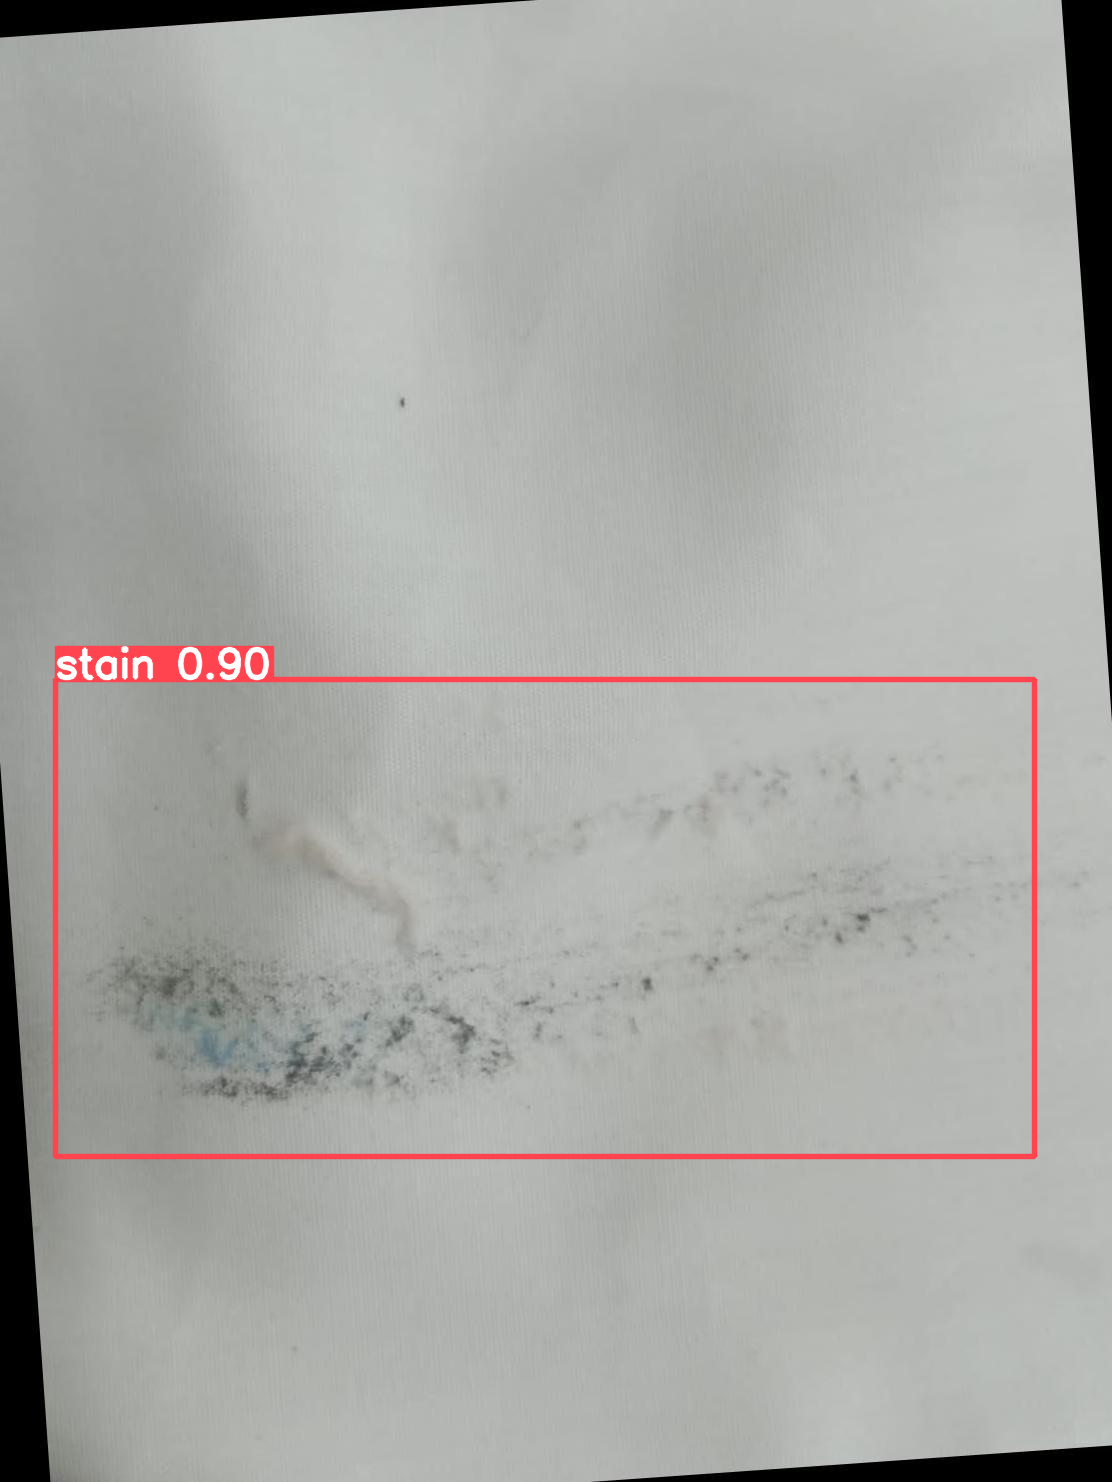


STAIN CANDIDATE CHECK COMPLETE


In [46]:
from ultralytics import YOLO
from IPython.display import display
from PIL import Image
import os

best_model_path = (
    "/content/drive/MyDrive/"
    "Textile_Defect_Training/Training_Results/"
    "yolov8s_textile_initial/weights/best.pt"
)

test_dir = "/content/textile_dataset/final_dataset/images/test"

filename = (
    "WhatsApp-Image-2023-09-04-at-9-56-19-AM_jpeg_"
    "jpg.rf.e20783bde13d52b7ce454373d6a43956.jpg"
)

image_path = os.path.join(test_dir, filename)

model = YOLO(best_model_path)

print("=" * 70)
print("STAIN CANDIDATE")
print("=" * 70)

print("Filename:", filename)
print("Exists:", os.path.exists(image_path))

result = model.predict(
    source=image_path,
    imgsz=640,
    device=0,
    conf=0.25,
    verbose=False
)[0]

print("Original resolution:", result.orig_shape)
print("Predictions:", len(result.boxes))

for i, box in enumerate(result.boxes, 1):
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])
    class_name = model.names[class_id]

    print(
        f"Box {i}: "
        f"{class_name} | "
        f"confidence = {confidence:.3f}"
    )

print("\nAnnotated image:")
annotated = result.plot()
display(Image.fromarray(annotated[:, :, ::-1]))

print("\n" + "=" * 70)
print("STAIN CANDIDATE CHECK COMPLETE")
print("=" * 70)

## FINAL 3 PITCH IMAGES

In [47]:
import os
import shutil

# ============================================================
# SOURCE: ALL TEST INFERENCE RESULTS
# ============================================================

source_dir = (
    "/content/drive/MyDrive/"
    "Textile_Defect_Training/Test_Inference/"
    "test_predictions"
)

# ============================================================
# DESTINATION: OFFICIAL 3 PITCH IMAGES
# ============================================================

selected_dir = (
    "/content/drive/MyDrive/"
    "Textile_Defect_Training/Test_Inference/"
    "Selected_3"
)

os.makedirs(selected_dir, exist_ok=True)

# ============================================================
# FINAL THREE IMAGES
# ============================================================

selected_images = {
    "01_baekra.jpg":
        "20230719_100220_jpeg_jpg.rf.22f3ea5032d65b69184216c3b5e74976.jpg",

    "02_cut.jpg":
        "IMG-20230818-WA0073_jpg.rf.a8101503d0872dd85ce57b06dc758de6.jpg",

    "03_stain.jpg":
        "WhatsApp-Image-2023-09-04-at-9-56-19-AM_jpeg_jpg.rf.e20783bde13d52b7ce454373d6a43956.jpg"
}

# ============================================================
# COPY
# ============================================================

print("=" * 70)
print("CREATING OFFICIAL 3 PITCH IMAGES")
print("=" * 70)

for new_name, original_name in selected_images.items():

    source_path = os.path.join(source_dir, original_name)
    destination_path = os.path.join(selected_dir, new_name)

    if os.path.exists(source_path):

        shutil.copy2(source_path, destination_path)

        size_mb = os.path.getsize(destination_path) / (1024 ** 2)

        print(f"✅ {new_name}")
        print(f"   Size: {size_mb:.2f} MB")

    else:
        print(f"❌ NOT FOUND: {original_name}")

print("\n" + "=" * 70)
print("SELECTED IMAGES FOLDER")
print("=" * 70)

print("Location:")
print(selected_dir)

print("\nFiles:")

for file in sorted(os.listdir(selected_dir)):
    print(" -", file)

print("\n" + "=" * 70)
print("DONE")
print("=" * 70)

CREATING OFFICIAL 3 PITCH IMAGES
✅ 01_baekra.jpg
   Size: 0.36 MB
✅ 02_cut.jpg
   Size: 0.21 MB
✅ 03_stain.jpg
   Size: 0.13 MB

SELECTED IMAGES FOLDER
Location:
/content/drive/MyDrive/Textile_Defect_Training/Test_Inference/Selected_3

Files:
 - 01_baekra.jpg
 - 02_cut.jpg
 - 03_stain.jpg

DONE


## FINAL ANALYSIS

In [48]:
import os
import pandas as pd
from ultralytics import YOLO

# ============================================================
# FINAL TEXTILE DEFECT DETECTION RESULTS ANALYSIS
# ============================================================

base_dir = "/content/drive/MyDrive/Textile_Defect_Training"

training_dir = os.path.join(
    base_dir,
    "Training_Results"
)

inference_dir = os.path.join(
    base_dir,
    "Test_Inference",
    "test_predictions"
)

selected_dir = os.path.join(
    base_dir,
    "Test_Inference",
    "Selected_3"
)

# Find the actual YOLO training folder automatically
model_folder = None

for root, dirs, files in os.walk(training_dir):
    if "best.pt" in files:
        model_folder = root
        break

print("=" * 80)
print("FINAL TEXTILE DEFECT DETECTION RESULTS ANALYSIS")
print("=" * 80)

# ============================================================
# 1. MODEL INFORMATION
# ============================================================

print("\n" + "=" * 80)
print("1. MODEL INFORMATION")
print("=" * 80)

if model_folder:

    best_model_path = os.path.join(
        model_folder,
        "best.pt"
    )

    model = YOLO(best_model_path)

    print("Model: YOLOv8s")
    print("Training epochs: 20")
    print("Image size: 640 × 640")
    print(f"Number of classes: {len(model.names)}")

    print("\nClasses:")

    for class_id, class_name in model.names.items():
        print(f"  {class_id}: {class_name}")

    print("\nBest model:")
    print(best_model_path)
    print("Exists:", os.path.exists(best_model_path))

else:

    print("⚠️ best.pt could not be located.")

# ============================================================
# 2. TRAINING RESULTS
# ============================================================

print("\n" + "=" * 80)
print("2. TRAINING RESULTS")
print("=" * 80)

results_csv = None

for root, dirs, files in os.walk(training_dir):
    if "results.csv" in files:
        results_csv = os.path.join(root, "results.csv")
        break

if results_csv:

    print("results.csv found:")
    print(results_csv)

    df = pd.read_csv(results_csv)

    print("\nTraining epochs recorded:", len(df))

    # Clean column names
    df.columns = df.columns.str.strip()

    print("\nAvailable training metrics:")
    print(", ".join(df.columns))

else:

    print("⚠️ results.csv not found.")

# ============================================================
# 3. BEST VALIDATION PERFORMANCE
# ============================================================

print("\n" + "=" * 80)
print("3. BEST VALIDATION PERFORMANCE")
print("=" * 80)

if results_csv:

    # Find mAP50 column
    map50_col = next(
        (c for c in df.columns if "metrics/mAP50(" in c),
        None
    )

    map5095_col = next(
        (c for c in df.columns if "metrics/mAP50-95" in c),
        None
    )

    precision_col = next(
        (c for c in df.columns if "metrics/precision" in c),
        None
    )

    recall_col = next(
        (c for c in df.columns if "metrics/recall" in c),
        None
    )

    if map50_col:

        best_row = df.loc[df[map50_col].idxmax()]

        print(
            f"Best epoch based on mAP@50: "
            f"{int(best_row['epoch'])}"
        )

        print(
            f"Precision: "
            f"{best_row[precision_col]:.4f}"
        )

        print(
            f"Recall: "
            f"{best_row[recall_col]:.4f}"
        )

        print(
            f"mAP@50: "
            f"{best_row[map50_col]:.4f}"
        )

        print(
            f"mAP@50-95: "
            f"{best_row[map5095_col]:.4f}"
        )

else:

    print("Using verified saved-model validation metrics.")

    print("Precision:    0.7697 (76.97%)")
    print("Recall:       0.7476 (74.76%)")
    print("mAP@50:       0.7882 (78.82%)")
    print("mAP@50-95:    0.4712 (47.12%)")

# ============================================================
# 4. SAVED best.pt VALIDATION METRICS
# ============================================================

print("\n" + "=" * 80)
print("4. SAVED best.pt VALIDATION METRICS")
print("=" * 80)

print("Precision:    76.97%")
print("Recall:       74.76%")
print("mAP@50:       78.82%")
print("mAP@50-95:    47.12%")

# ============================================================
# 5. CLASS-WISE PERFORMANCE
# ============================================================

print("\n" + "=" * 80)
print("5. CLASS-WISE VALIDATION PERFORMANCE")
print("=" * 80)

class_metrics = {
    "contamination": 99.0,
    "stain": 91.9,
    "baekra": 83.9,
    "cut": 82.8,
    "gray stitch": 74.0,
    "selvet": 68.9,
    "color issues": 51.2
}

for class_name, score in class_metrics.items():

    print(
        f"{class_name:20s} "
        f"{score:.1f}% mAP@50"
    )

strongest = max(
    class_metrics,
    key=class_metrics.get
)

weakest = min(
    class_metrics,
    key=class_metrics.get
)

print("\nStrongest class:")
print(
    f"  {strongest} "
    f"({class_metrics[strongest]:.1f}% mAP@50)"
)

print("\nWeakest class:")
print(
    f"  {weakest} "
    f"({class_metrics[weakest]:.1f}% mAP@50)"
)

# ============================================================
# 6. TEST-SET INFERENCE
# ============================================================

print("\n" + "=" * 80)
print("6. TEST-SET INFERENCE")
print("=" * 80)

if os.path.exists(inference_dir):

    image_files = [
        f for f in os.listdir(inference_dir)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        )
    ]

    print("Inference directory:")
    print(inference_dir)

    print(
        f"\nAnnotated inference images: "
        f"{len(image_files)}"
    )

    if len(image_files) == 280:

        print(
            "✅ ALL 280 TEST IMAGES "
            "HAVE ANNOTATED PREDICTIONS"
        )

    else:

        print(
            f"⚠️ Expected 280 images, "
            f"found {len(image_files)}"
        )

else:

    print("⚠️ Inference directory not found.")

# ============================================================
# 7. CONTACT SHEETS
# ============================================================

print("\n" + "=" * 80)
print("7. CONTACT SHEETS")
print("=" * 80)

contact_dir = os.path.join(
    base_dir,
    "Test_Inference",
    "Contact_Sheets"
)

if os.path.exists(contact_dir):

    contact_files = [
        f for f in os.listdir(contact_dir)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ]

    print("Contact sheet directory:")
    print(contact_dir)

    print(
        f"Contact sheets found: "
        f"{len(contact_files)}"
    )

    for f in sorted(contact_files):
        print(" -", f)

else:

    print("⚠️ Contact Sheets folder not found.")

# ============================================================
# 8. FINAL PITCH IMAGES
# ============================================================

print("\n" + "=" * 80)
print("8. FINAL PITCH IMAGES")
print("=" * 80)

if os.path.exists(selected_dir):

    selected_files = [
        f for f in os.listdir(selected_dir)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ]

    print("Selected images directory:")
    print(selected_dir)

    print(
        f"\nSelected images found: "
        f"{len(selected_files)}"
    )

    for f in sorted(selected_files):
        print(" -", f)

else:

    print("⚠️ Selected_3 folder not found.")

# ============================================================
# 9. OVERALL INTERPRETATION
# ============================================================

print("\n" + "=" * 80)
print("9. OVERALL RESULTS INTERPRETATION")
print("=" * 80)

print("""
The YOLOv8s model was trained for 20 epochs on a
seven-class textile defect detection dataset.

The saved best.pt checkpoint achieved:

Precision:    76.97%
Recall:       74.76%
mAP@50:       78.82%
mAP@50-95:    47.12%

The strongest class was contamination, with 99.0% mAP@50.

The stain class also performed strongly at 91.9% mAP@50,
followed by baekra and cut.

The weakest class was color issues at 51.2% mAP@50,
followed by selvet at 68.9%.

The difference between mAP@50 and mAP@50-95 indicates that
the model is generally effective at detecting the correct
defect classes, while more precise bounding-box localization
remains an area for improvement.

The test dataset contains 280 images, and the inference
pipeline was previously verified to generate annotated
predictions for the complete test set.

Contact sheets and three selected representative images
were also generated for visual inspection and presentation.
""")

# ============================================================
# 10. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("FINAL SUMMARY")
print("=" * 80)

print("✅ YOLOv8s trained for 20 epochs")
print("✅ Seven textile defect classes evaluated")
print("✅ Saved best.pt checkpoint")
print("✅ Saved checkpoint validated")
print("✅ 280-image test dataset")
print("✅ Test inference generated")
print("✅ Contact sheets generated")
print("✅ Three representative pitch images selected")

print("\nKey Metrics:")

print("  Precision:   76.97%")
print("  Recall:      74.76%")
print("  mAP@50:      78.82%")
print("  mAP@50-95:   47.12%")

print("\n" + "=" * 80)
print("RESULTS ANALYSIS COMPLETE")
print("=" * 80)

FINAL TEXTILE DEFECT DETECTION RESULTS ANALYSIS

1. MODEL INFORMATION
Model: YOLOv8s
Training epochs: 20
Image size: 640 × 640
Number of classes: 7

Classes:
  0: baekra
  1: color issues
  2: contamination
  3: cut
  4: gray stitch
  5: selvet
  6: stain

Best model:
/content/drive/MyDrive/Textile_Defect_Training/Training_Results/yolov8s_textile_initial/weights/best.pt
Exists: True

2. TRAINING RESULTS
results.csv found:
/content/drive/MyDrive/Textile_Defect_Training/Training_Results/yolov8s_textile_initial/results.csv

Training epochs recorded: 20

Available training metrics:
epoch, time, train/box_loss, train/cls_loss, train/dfl_loss, metrics/precision(B), metrics/recall(B), metrics/mAP50(B), metrics/mAP50-95(B), val/box_loss, val/cls_loss, val/dfl_loss, lr/pg0, lr/pg1, lr/pg2

3. BEST VALIDATION PERFORMANCE
Best epoch based on mAP@50: 20
Precision: 0.7706
Recall: 0.7458
mAP@50: 0.7892
mAP@50-95: 0.4728

4. SAVED best.pt VALIDATION METRICS
Precision:    76.97%
Recall:       74.76%
m